# 🛡️ PayPal Fraud Detection: catching fraudsters early

**Goal:** find users who signed up only to steal money, as early as possible, and decide what to do with them:
lock the account, send it to a human agent, or both.

**How this notebook is organised**

1. What the data can (and cannot) answer
2. Data audit: quality issues found
3. What fraudsters look like
4. Framing the problem: real-time user scoring
5. Feature engineering
6. Models and benchmarks
7. How early can we catch them?
8. Business evaluation: money saved vs. good users disturbed
9. Operational policy: `patrol(user_id)`
10. Summary, limitations and next steps

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

SEED = 123
np.random.seed(SEED)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

FRAUD, NORMAL = '#d62728', '#7f7f7f'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3})
IMG = 'images/'

## 1. What the data can (and cannot) answer

Two tables:

* **users** (one row per user): profile at sign-up such as country, phone country, KYC status, birth year,
  failed sign-ins, and the label `is_fraud`.
* **transactions** (one row per transaction): type, state, amount, currency, merchant, entry method and
  the internal `source` system that processed it.

The label sits on the **user**, not on the transaction. We know *who* is a fraudster but not *which*
transaction was fraudulent or *when* they were caught. So the right question is:

> *Given everything we know about a user **up to now**, how likely is it that they are a fraudster?*

Asked after every transaction, this gives a real-time risk score that can stop a fraudster mid-way.

In [2]:
users = pd.read_csv('data/paypal_users.csv', parse_dates=['created_date'])
tx = pd.read_csv('data/paypal_transactions.csv', parse_dates=['created_date'])
print(f'users: {users.shape},  transactions: {tx.shape}')
print(f"fraudsters: {users.is_fraud.sum()} of {len(users)} users ({users.is_fraud.mean():.1%})")
users.head(3)

users: (9944, 10),  transactions: (638742, 12)
fraudsters: 298 of 9944 users (3.0%)


,id,has_email,phone_country,terms_version,created_date,country,birth_year,kyc,failed_sign_in_attempts,is_fraud
0,1872820f-e3ac-4c02-bdc7-727897b60043,1,GB||JE||IM||GG,2024-05-23,2023-08-05 07:33:33.341,GB,1971,PASSED,0,0
1,545ff94d-66f8-4bea-b398-84425fb2301e,1,GB||JE||IM||GG,2023-12-31,2023-03-06 10:18:59.427,GB,1982,PASSED,0,0
2,10376f1a-a28a-4885-8daa-c8ca496026bb,1,ES,2024-09-18,2024-05-29 04:41:24.672,ES,1973,PASSED,0,0


In [3]:
tx.head(3)

,currency,state,created_date,merchant_category,merchant_country,entry_method,user_id,type,source,id,amount_usd,is_crypto
0,GBP,COMPLETED,2023-12-19 12:46:20.294,cafe,GBR,cont,8f99c254-7cf2-4e35-b7e4-53804d42445d,CARD_PAYMENT,GAIA,b3332e6f-7865-4d6e-b6a5-370bc75568d8,220,False
1,EUR,COMPLETED,2023-12-19 12:38:47.232,bar,AUS,cont,ed773c34-2b83-4f70-a691-6a7aa1cb9f11,CARD_PAYMENT,GAIA,853d9ff8-a007-40ef-91a2-7d81e29a309a,2885,False
2,EUR,COMPLETED,2023-12-19 12:34:39.668,NaN,CZE,cont,eb349cc1-e986-4bf4-bb75-72280a7b8680,CARD_PAYMENT,GAIA,04de8238-7828-4e46-91f1-050a9aa7a9df,1198,False


## 2. Data audit

In [4]:
audit = pd.DataFrame({
    'missing %': pd.concat([users.isna().mean(), tx.isna().mean()]).mul(100).round(1),
    'unique': pd.concat([users.nunique(), tx.nunique()]),
})
audit[audit['missing %'] > 0]

,missing %,unique
terms_version,15.4,7
merchant_category,67.3,115
merchant_country,30.0,303


In [5]:
print('Transactions per user (users with any):')
print(tx.groupby('user_id').size().describe().round(1))
no_tx = ~users.id.isin(tx.user_id)
print(f'\nUsers with no transactions: {no_tx.sum()}, of which fraudsters: {users[no_tx].is_fraud.sum()}')
print(f'Transaction ids duplicated: {tx.id.duplicated().sum()},  orphan transactions: {(~tx.user_id.isin(users.id)).sum()}')
print(f'Date range users: {users.created_date.min():%Y-%m-%d} to {users.created_date.max():%Y-%m-%d}')
print(f'Date range transactions: {tx.created_date.min():%Y-%m-%d} to {tx.created_date.max():%Y-%m-%d}')

Transactions per user (users with any):
count    7748.0
mean       82.4
std       159.6
min         1.0
25%         6.0
50%        26.0
75%        83.0
max      2725.0
dtype: float64

Users with no transactions: 2196, of which fraudsters: 1
Transaction ids duplicated: 0,  orphan transactions: 0
Date range users: 2022-01-01 to 2024-07-29
Date range transactions: 2022-01-01 to 2024-07-29


In [6]:
# amount_usd looks like cents: median 1,429 -> $14.29 for a typical card payment
print(tx.amount_usd.describe(percentiles=[.5, .9, .99, .999]).round(0))
crypto = ['BTC', 'ETH', 'LTC', 'XRP']
print('\nLargest amounts by currency:')
tx.nlargest(6, 'amount_usd')[['type', 'currency', 'amount_usd', 'state']]

count    6.387420e+05
mean     7.422357e+06
std      2.334350e+09
min      0.000000e+00
50%      1.429000e+03
90%      1.669400e+04
99%      1.260680e+05
99.9%    2.521368e+06
max      1.657095e+12
Name: amount_usd, dtype: float64

Largest amounts by currency:


,type,currency,amount_usd,state
94674,P2P,BTC,1657094872409,DECLINED
228068,P2P,BTC,828547436204,DECLINED
305896,CARD_PAYMENT,BTC,108226920914,DECLINED
59757,CARD_PAYMENT,LTC,66490630540,DECLINED
68027,CARD_PAYMENT,LTC,61671004519,DECLINED
225116,CARD_PAYMENT,BTC,44668226821,DECLINED


In [7]:
# Fraud rate by sign-up quarter: recent cohorts look "clean" because fraud is not discovered yet
cohort = users.groupby(users.created_date.dt.to_period('Q')).is_fraud.agg(['count', 'mean'])
cohort['mean'] = (cohort['mean'] * 100).round(1)
cohort.rename(columns={'count': 'users', 'mean': 'fraud %'}).T

created_date,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3
users,292.0,385.0,535.0,444.0,440.0,597.0,777.0,1363.0,2063.0,2324.0,724.0
fraud %,1.4,0.5,0.6,0.5,1.1,4.2,5.7,2.9,5.0,2.9,0.3


**Data quality findings**

| # | Issue | What I did |
|---|---|---|
| 1 | `amount_usd` is stored in **cents** (median 1,429 ≈ a $14 coffee). | Divide by 100. |
| 2 | Crypto rows (BTC, ETH, LTC) have absurd amounts (up to 10¹² "USD"), so they were never converted from coin units. | Cap all amounts at the 99.9th percentile of non-crypto transactions. |
| 3 | `merchant_category` (67%) and `merchant_country` (30%) are missing, mostly because top-ups and transfers have no merchant. | Use missingness as information; never impute. |
| 4 | 2,196 users have **no transactions** (only 1 fraudster among them). | They cannot move money, so they are left out of the transaction model. |
| 5 | **Label maturity:** users who signed up in 2024 Q3 show 0.3% fraud vs. 3 to 5% before. Their fraud simply hasn't been discovered yet. | Treat recent cohorts with care; no sign-up date features that could learn "new = safe". |
| 6 | `terms_version` 2024-09-18 has 0% fraud, and is newer than the last date in the data. | Not used as a feature (it reflects timing, not behaviour). |

## 3. What fraudsters look like

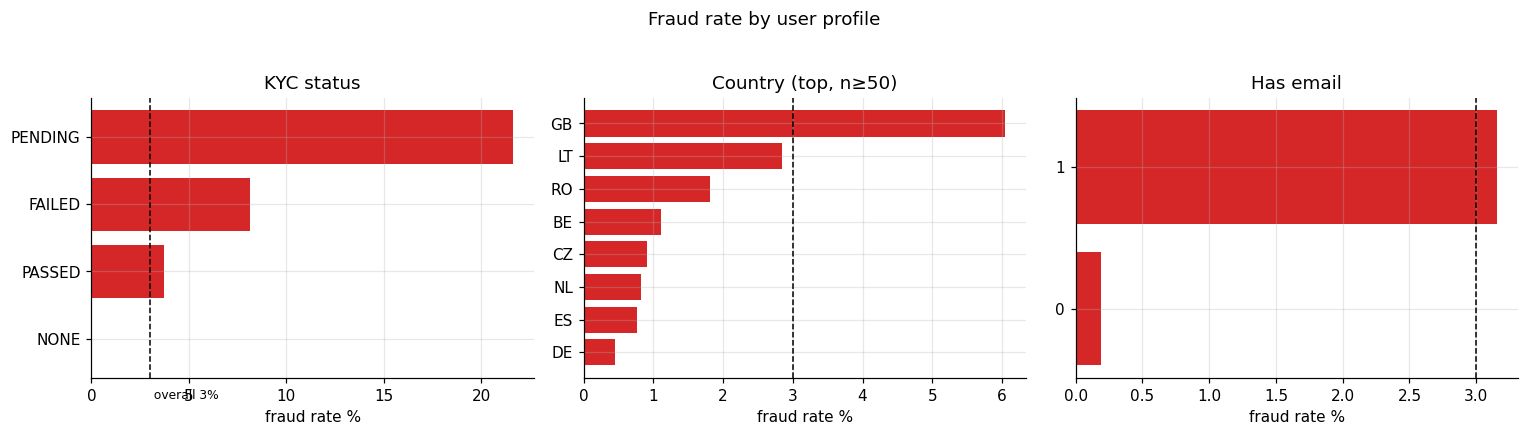

In [8]:
def fraud_rate(col, data=users, min_n=50):
    g = data.groupby(col).is_fraud.agg(users='count', fraud_rate='mean')
    return g[g.users >= min_n].sort_values('fraud_rate', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
base = users.is_fraud.mean()
for ax, col, title in zip(axes, ['kyc', 'country', 'has_email'], ['KYC status', 'Country (top, n≥50)', 'Has email']):
    r = fraud_rate(col).head(8)
    ax.barh(r.index.astype(str)[::-1], r.fraud_rate[::-1] * 100, color=FRAUD)
    ax.axvline(base * 100, color='k', ls='--', lw=1)
    ax.set_title(title); ax.set_xlabel('fraud rate %')
axes[0].text(base * 100, -0.9, ' overall 3%', fontsize=8)
plt.suptitle('Fraud rate by user profile', y=1.03)
plt.tight_layout(); plt.savefig(IMG + 'fraud_rate_profile.png', bbox_inches='tight'); plt.show()

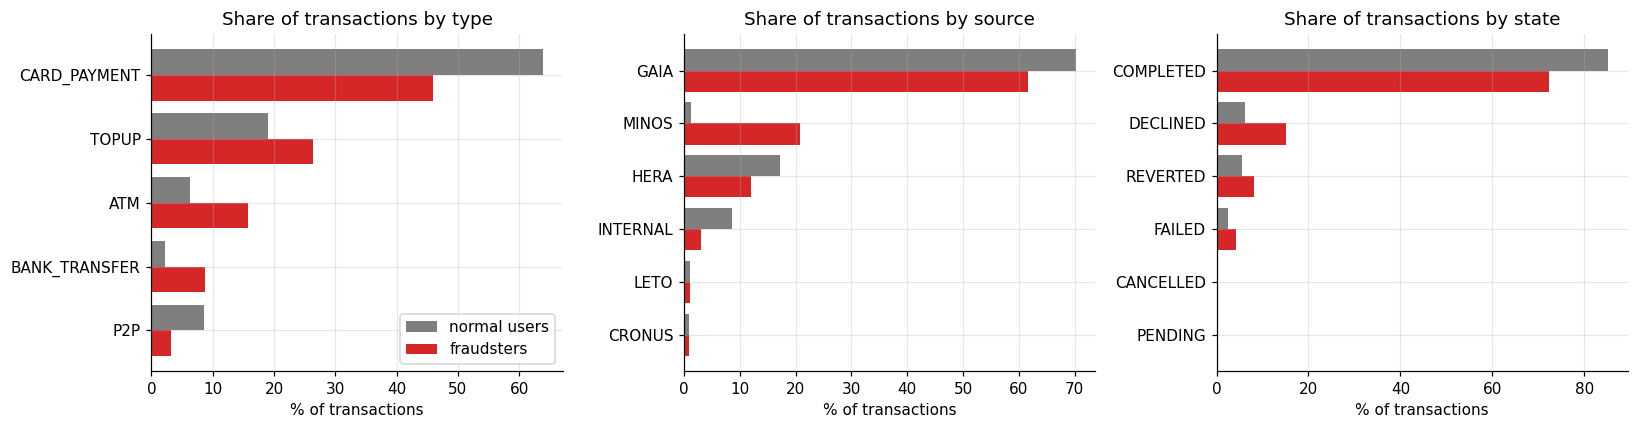

,normal,fraud,lift
source,,,
GAIA,0.702,0.617,0.879
MINOS,0.012,0.208,16.746
HERA,0.172,0.121,0.701
INTERNAL,0.086,0.031,0.362
LETO,0.011,0.010,0.960
CRONUS,0.009,0.008,0.958


In [9]:
t = tx.merge(users[['id', 'is_fraud']].rename(columns={'id': 'user_id'}), on='user_id')

def mix(col):
    m = pd.crosstab(t[col], t.is_fraud, normalize='columns')
    m.columns = ['normal', 'fraud']
    m['lift'] = m.fraud / m.normal
    return m.sort_values('fraud', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['type', 'source', 'state']):
    m = mix(col).head(6)[::-1]
    y = np.arange(len(m))
    ax.barh(y + 0.2, m.normal * 100, 0.4, color=NORMAL, label='normal users')
    ax.barh(y - 0.2, m.fraud * 100, 0.4, color=FRAUD, label='fraudsters')
    ax.set_yticks(y, m.index); ax.set_title(f'Share of transactions by {col}'); ax.set_xlabel('% of transactions')
axes[0].legend()
plt.tight_layout(); plt.savefig(IMG + 'transaction_mix.png', bbox_inches='tight'); plt.show()
mix('source').round(3).head(6)

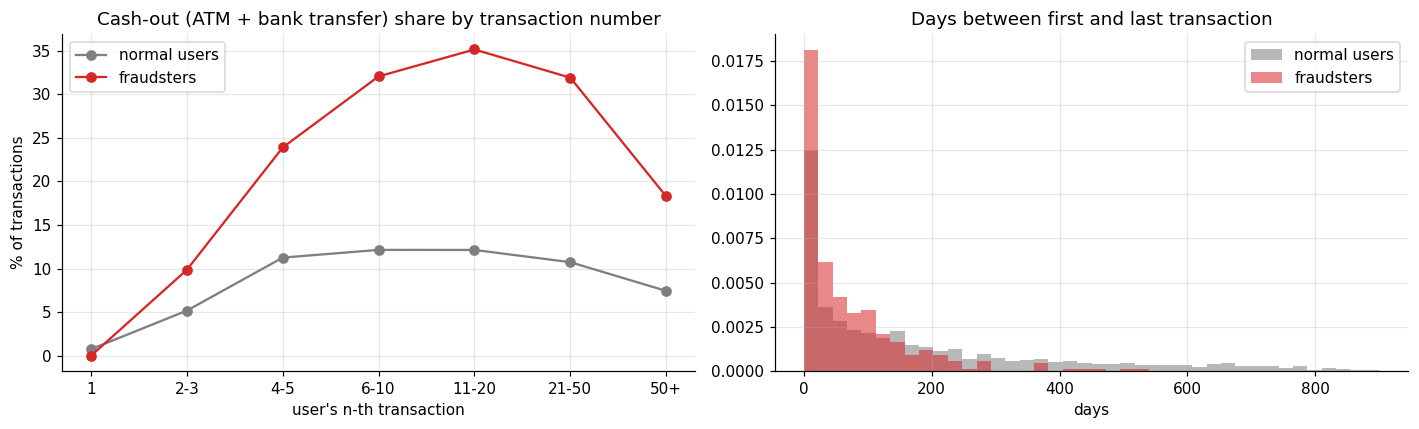

fraud
0    99.0
1    38.0
Name: active_days, dtype: float64


In [10]:
t = t.sort_values(['user_id', 'created_date'])
t['tx_n'] = t.groupby('user_id').cumcount() + 1
bins = [0, 1, 3, 5, 10, 20, 50, np.inf]
labels = ['1', '2-3', '4-5', '6-10', '11-20', '21-50', '50+']
t['stage'] = pd.cut(t.tx_n, bins, labels=labels)
cash = t.type.isin(['ATM', 'BANK_TRANSFER'])
stage = t.assign(cash=cash).groupby(['stage', 'is_fraud'], observed=True).cash.mean().unstack() * 100

life = t.groupby('user_id').agg(fraud=('is_fraud', 'first'), first=('created_date', 'min'), last=('created_date', 'max'))
life['active_days'] = (life['last'] - life['first']).dt.days

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(labels, stage[0], 'o-', color=NORMAL, label='normal users')
axes[0].plot(labels, stage[1], 'o-', color=FRAUD, label='fraudsters')
axes[0].set_title('Cash-out (ATM + bank transfer) share by transaction number')
axes[0].set_xlabel("user's n-th transaction"); axes[0].set_ylabel('% of transactions'); axes[0].legend()
for f, c, lab in [(0, NORMAL, 'normal users'), (1, FRAUD, 'fraudsters')]:
    axes[1].hist(life[life.fraud == f].active_days, bins=40, range=(0, 900), density=True, alpha=0.55, color=c, label=lab)
axes[1].set_title('Days between first and last transaction'); axes[1].set_xlabel('days'); axes[1].legend()
plt.tight_layout(); plt.savefig(IMG + 'fraud_lifecycle.png', bbox_inches='tight'); plt.show()
print(life.groupby('fraud').active_days.median())

**What stands out**

* **Profile:** fraud is concentrated in **GB** accounts (6% vs. under 1% for most of Europe), users whose
  **KYC is PENDING (22%) or FAILED (8%)**, and users who gave an email. Users who never did KYC are almost never
  fraudsters, probably because without KYC they can barely move money.
* **Behaviour:** fraudsters pay in **GBP 92%** of the time, and push money out through **bank transfers (4× more)**
  and **ATM withdrawals (2.5× more)**. Their transactions are **declined 2.4× more often**.
* **The `MINOS` source** handles 21% of fraudster transactions but only 1% of normal ones (17× lift). It
  handles top-ups and bank transfers, so it is probably a specific funding channel that fraudsters prefer.
* **Life cycle:** fraudsters top up first (like everyone) and then **switch to cashing out within 5 to 10 transactions**.
  Their accounts live a median of ~38 days vs. ~99 for normal users, which is consistent with being caught and closed.

These patterns build up over a user's history, which suggests scoring the **history so far**, not a single transaction.

## 4. Framing: real-time user scoring

* **Unit of prediction:** a *(user, moment)* pair. After each transaction, we compute features from the user's profile
  plus **only the transactions up to and including that one**, and ask the model for a risk score.
* **Label:** the user's `is_fraud` flag, attached to all of their moments.
* **No leakage from the future:** every feature is a running (cumulative) value, so the score at transaction #5
  knows nothing about transaction #6. Features like "total account lifetime" (which tells you the account was closed)
  are deliberately excluded.
* **Split by user** (60% train, 20% validation, 20% test, stratified on fraud). The same person never appears in both
  training and test.
* **Weighting:** heavy users have hundreds of moments. Each user's moments are weighted to sum to 1, so the model learns
  about *people*, not about the busiest accounts. Fraudsters are up-weighted to balance the 3% base rate.

## 5. Feature engineering

In [11]:
def clean_transactions(tx):
    t = tx.copy()
    t['amount'] = t.amount_usd / 100                           # cents -> dollars
    cap = t.loc[~t.currency.isin(crypto), 'amount'].quantile(0.999)
    t['amount'] = t.amount.clip(upper=cap)                     # unconverted crypto amounts
    return t, cap

def user_profile(users):
    u = users.rename(columns={'id': 'user_id', 'created_date': 'signup'}).copy()
    u['phone_mismatch'] = (u.country != u.phone_country.str[:2]).astype(int)
    u['age'] = 2024 - u.birth_year
    u['terms_missing'] = u.terms_version.isna().astype(int)
    u['country_GB'] = (u.country == 'GB').astype(int)
    for k in ['PASSED', 'FAILED', 'PENDING', 'NONE']:
        u[f'kyc_{k}'] = (u.kyc == k).astype(int)
    return u

PROFILE = ['has_email', 'failed_sign_in_attempts', 'phone_mismatch', 'age', 'terms_missing', 'country_GB',
           'kyc_PASSED', 'kyc_FAILED', 'kyc_PENDING', 'kyc_NONE']

CATS = {'type': ['ATM', 'BANK_TRANSFER', 'CARD_PAYMENT', 'P2P', 'TOPUP'],
        'state': ['COMPLETED', 'DECLINED', 'REVERTED', 'FAILED'],
        'entry_method': ['manu', 'misc', 'chip', 'cont', 'mags'],
        'source': ['MINOS', 'GAIA', 'HERA', 'INTERNAL', 'CRONUS', 'LIMOS']}

def build_moments(tx, users):
    """One row per transaction: user profile + running history up to and including that transaction."""
    t, _ = clean_transactions(tx)
    u = user_profile(users)
    t = (t.merge(u[['user_id', 'signup', 'country', 'is_fraud'] + PROFILE], on='user_id')
          .sort_values(['user_id', 'created_date']).reset_index(drop=True))
    g = t.groupby('user_id')
    F = t[PROFILE].copy()
    F['tx_n'] = g.cumcount() + 1
    F['days_since_signup'] = (t.created_date - t.signup).dt.total_seconds() / 86400
    F['hours_since_prev'] = g.created_date.diff().dt.total_seconds().div(3600).fillna(-1)
    F['tx_per_day'] = F.tx_n / (F.days_since_signup + 1)
    F['tx_last_24h'] = (t.set_index('created_date').groupby('user_id').id
                         .rolling('24h').count().reset_index(drop=True).values)
    F['log_amount'] = np.log1p(t.amount)
    F['log_max_amount'] = np.log1p(g.amount.cummax())
    F['log_cum_amount'] = np.log1p(g.amount.cumsum())
    for col, values in CATS.items():
        for v in values:
            is_v = (t[col] == v).astype(float)
            F[f'is_{col}_{v}'] = is_v                                    # this transaction
            F[f'share_{col}_{v}'] = is_v.groupby(t.user_id).cumsum() / F.tx_n   # history so far
    F['share_gbp'] = (t.currency == 'GBP').astype(float).groupby(t.user_id).cumsum() / F.tx_n
    foreign = (t.merchant_country.notna() & (t.merchant_country.str[:2] != t.country)).astype(float)
    F['share_foreign_merchant'] = foreign.groupby(t.user_id).cumsum() / F.tx_n
    done = t.state == 'COMPLETED'
    cash_out = np.where(done & t.type.isin(['ATM', 'BANK_TRANSFER', 'P2P']), t.amount, 0)
    top_up = np.where(done & (t.type == 'TOPUP'), t.amount, 0)
    co = pd.Series(cash_out).groupby(t.user_id).cumsum()
    tu = pd.Series(top_up).groupby(t.user_id).cumsum()
    F['log_cum_cash_out'] = np.log1p(co)
    F['cash_out_to_top_up'] = co / (tu + 1)
    return t, F

t, F = build_moments(tx, users)
print(f'{F.shape[0]:,} moments x {F.shape[1]} features')
F.head(3)

638,742 moments x 62 features


,has_email,failed_sign_in_attempts,phone_mismatch,age,terms_missing,country_GB,kyc_PASSED,kyc_FAILED,kyc_PENDING,kyc_NONE,tx_n,days_since_signup,hours_since_prev,tx_per_day,tx_last_24h,log_amount,log_max_amount,log_cum_amount,is_type_ATM,share_type_ATM,...,is_entry_method_cont,share_entry_method_cont,is_entry_method_mags,share_entry_method_mags,is_source_MINOS,share_source_MINOS,is_source_GAIA,share_source_GAIA,is_source_HERA,share_source_HERA,is_source_INTERNAL,share_source_INTERNAL,is_source_CRONUS,share_source_CRONUS,is_source_LIMOS,share_source_LIMOS,share_gbp,share_foreign_merchant,log_cum_cash_out,cash_out_to_top_up
0,1,0,0,35,0,0,1,0,0,0,1,5.283538,-1.000000,0.159146,1.0,0.131028,0.131028,0.131028,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,0,0,35,0,0,1,0,0,0,2,5.283740,0.004857,0.318282,2.0,2.766319,2.766319,2.775086,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0,0,35,0,0,1,0,0,0,3,48.955102,1048.112691,0.060054,1.0,4.324265,4.324265,4.505902,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Features in plain words**

* **Profile (10):** KYC status, GB account, email, phone country ≠ account country, age, failed sign-ins, missing terms version.
* **This transaction:** type, state, entry method, source, amount.
* **History so far:** number of transactions, days since sign-up, speed (transactions per day, last 24h, hours since
  previous), the share of history in each type/state/entry method/source, share in GBP, share at foreign merchants,
  largest and total amount, and **cash-out vs. top-up ratio** (money taken out per dollar put in).

## 6. Models and benchmarks

In [12]:
y = t.is_fraud.values
ulist = t.groupby('user_id').is_fraud.first().reset_index()
train_u, rest = train_test_split(ulist, test_size=0.4, stratify=ulist.is_fraud, random_state=SEED)
valid_u, test_u = train_test_split(rest, test_size=0.5, stratify=rest.is_fraud, random_state=SEED)
split = {name: t.user_id.isin(s.user_id).values for name, s in [('train', train_u), ('valid', valid_u), ('test', test_u)]}
for name, s in [('train', train_u), ('valid', valid_u), ('test', test_u)]:
    print(f'{name:5}: {len(s):5} users, {s.is_fraud.sum():3} fraudsters, {split[name].sum():7,} moments')

n_user_tx = t.groupby('user_id').user_id.transform('size').values
pos_weight = (1 - ulist.is_fraud.mean()) / ulist.is_fraud.mean()
w_user = 1 / n_user_tx                       # each user counts once
w_train = w_user * np.where(y == 1, pos_weight, 1)

train:  4648 users, 178 fraudsters, 387,228 moments
valid:  1550 users,  59 fraudsters, 127,537 moments
test :  1550 users,  60 fraudsters, 123,977 moments


In [13]:
def user_scores(score, mask, upto=None):
    """Highest score a user reached (optionally within their first `upto` transactions)."""
    d = pd.DataFrame({'user_id': t.user_id[mask].values, 'y': y[mask], 'p': score, 'n': F.tx_n[mask].values})
    if upto is not None:
        d = d[d.n <= upto]
    return d.groupby('user_id').agg(y=('y', 'first'), p=('p', 'max'))

def report(name, score, mask):
    us = user_scores(score, mask)
    return {'model': name,
            'moment AUC': roc_auc_score(y[mask], score, sample_weight=w_user[mask]),
            'moment PR-AUC': average_precision_score(y[mask], score, sample_weight=w_user[mask]),
            'user AUC': roc_auc_score(us.y, us.p),
            'user PR-AUC': average_precision_score(us.y, us.p)}

# Benchmark 1: a hand-written rule an analyst might use
def rule_score(X):
    return (2 * X.kyc_PENDING + X.kyc_FAILED + X.country_GB + X.share_source_MINOS
            + X.share_type_BANK_TRANSFER + X.share_type_ATM + X.share_state_DECLINED).values

# Benchmark 2: profile only (what we know at sign-up, before any transaction)
prof = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced'))
prof.fit(F.loc[split['train'], PROFILE], y[split['train']], logisticregression__sample_weight=w_user[split['train']])

# Benchmark 3: logistic regression on all features
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.3))
logit.fit(F[split['train']], y[split['train']], logisticregression__sample_weight=w_train[split['train']])

rows = []
for name, f in [('Analyst rule', lambda X: rule_score(X)),
                ('Profile only (logistic)', lambda X: prof.predict_proba(X[PROFILE])[:, 1]),
                ('All features (logistic)', lambda X: logit.predict_proba(X)[:, 1])]:
    rows.append(report(name, f(F[split['valid']]), split['valid']))
pd.DataFrame(rows).set_index('model').round(3)

,moment AUC,moment PR-AUC,user AUC,user PR-AUC
model,,,,
Analyst rule,0.839,0.212,0.872,0.283
Profile only (logistic),0.790,0.110,0.790,0.110
All features (logistic),0.955,0.619,0.951,0.639


**XGBoost tuning.** Random search over tree depth, learning rate and regularisation, scored on **validation user PR-AUC**.
PR-AUC focuses on how clean the top of the ranking is, which is what matters when only ~3% of users are fraudsters.

In [14]:
rng = np.random.default_rng(SEED)
space = {'max_depth': [3, 4, 5, 6], 'learning_rate': [0.02, 0.03, 0.05, 0.08], 'n_estimators': [300, 500, 800],
         'subsample': [0.7, 0.8, 0.9], 'colsample_bytree': [0.5, 0.7, 0.9], 'min_child_weight': [1e-3, 1e-2, 0.1],
         'reg_lambda': [1, 5, 10]}
trials = []
for i in range(12):
    params = {k: v[rng.integers(len(v))] for k, v in space.items()}
    m = xgb.XGBClassifier(**params, eval_metric='aucpr', random_state=SEED, n_jobs=-1)
    m.fit(F[split['train']], y[split['train']], sample_weight=w_train[split['train']])
    r = report('xgb', m.predict_proba(F[split['valid']])[:, 1], split['valid'])
    trials.append({**params, 'user PR-AUC': r['user PR-AUC'], 'user AUC': r['user AUC']})
trials = pd.DataFrame(trials).sort_values('user PR-AUC', ascending=False)
trials.head(5).round(3)

,max_depth,learning_rate,n_estimators,subsample,colsample_bytree,min_child_weight,reg_lambda,user PR-AUC,user AUC
4,4,0.05,300,0.8,0.7,0.10,10,0.754,0.954
8,4,0.08,300,0.8,0.7,0.10,5,0.753,0.957
10,5,0.03,500,0.9,0.7,0.10,10,0.751,0.952
3,5,0.03,300,0.7,0.9,0.10,1,0.750,0.950
11,4,0.05,500,0.8,0.5,0.01,5,0.749,0.953


In [15]:
best = trials.iloc[0][list(space)].to_dict()
best = {k: (int(v) if k in ('max_depth', 'n_estimators') else float(v)) for k, v in best.items()}
model = xgb.XGBClassifier(**best, eval_metric='aucpr', random_state=SEED, n_jobs=-1)
model.fit(F[split['train']], y[split['train']], sample_weight=w_train[split['train']])
print('Chosen parameters:', best)

score = {s: model.predict_proba(F[split[s]])[:, 1] for s in ['valid', 'test']}
rows = []
for s in ['valid', 'test']:
    X = F[split[s]]
    for name, sc in [('Analyst rule', rule_score(X)),
                     ('Profile only (logistic)', prof.predict_proba(X[PROFILE])[:, 1]),
                     ('All features (logistic)', logit.predict_proba(X)[:, 1]),
                     ('XGBoost (real-time)', score[s])]:
        rows.append({'set': s, **report(name, sc, split[s])})
results = pd.DataFrame(rows).set_index(['set', 'model']).round(3)
results

Chosen parameters: {'max_depth': 4, 'learning_rate': 0.05, 'n_estimators': 300, 'subsample': 0.8, 'colsample_bytree': 0.7, 'min_child_weight': 0.1, 'reg_lambda': 10.0}


moment AUC  moment PR-AUC  user AUC  user PR-AUC
set   model                                                                    
valid Analyst rule                  0.839          0.212     0.872        0.283
      Profile only (logistic)       0.790          0.110     0.790        0.110
      All features (logistic)       0.955          0.619     0.951        0.639
      XGBoost (real-time)           0.965          0.689     0.954        0.754
test  Analyst rule                  0.858          0.256     0.903        0.325
      Profile only (logistic)       0.826          0.206     0.826        0.206
      All features (logistic)       0.968          0.684     0.988        0.769
      XGBoost (real-time)           0.982          0.794     0.990        0.850

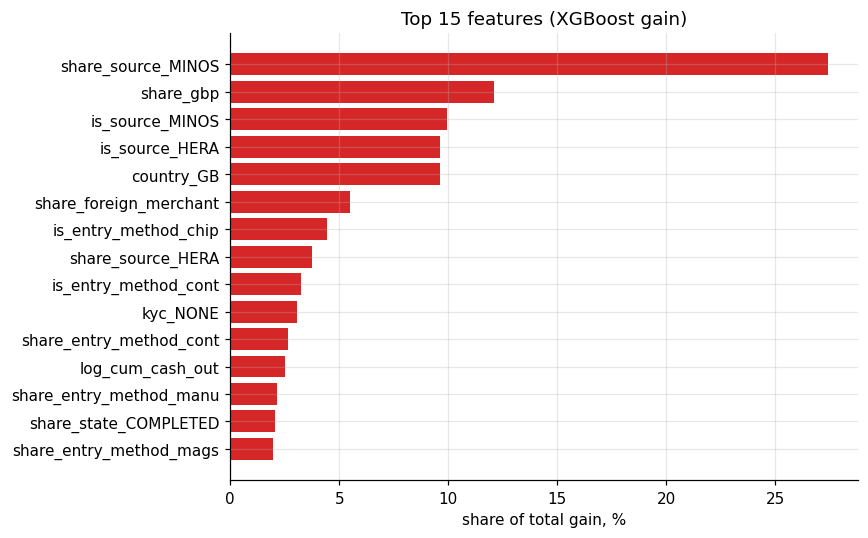

In [16]:
imp = pd.Series(model.get_booster().get_score(importance_type='gain')).sort_values(ascending=False).head(15)
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index[::-1], imp.values[::-1] * 100, color=FRAUD)
ax.set_xlabel('share of total gain, %'); ax.set_title('Top 15 features (XGBoost gain)')
plt.tight_layout(); plt.savefig(IMG + 'feature_importance.png', bbox_inches='tight'); plt.show()

The real-time XGBoost beats every benchmark. The top features match the EDA: **MINOS share, GBP share, GB account,
the processing source, KYC status, ATM / bank-transfer behaviour and manual card entry**.
Profile alone is already useful (KYC and country), but transaction behaviour is what pushes the model to high precision.

## 7. How early can we catch them?

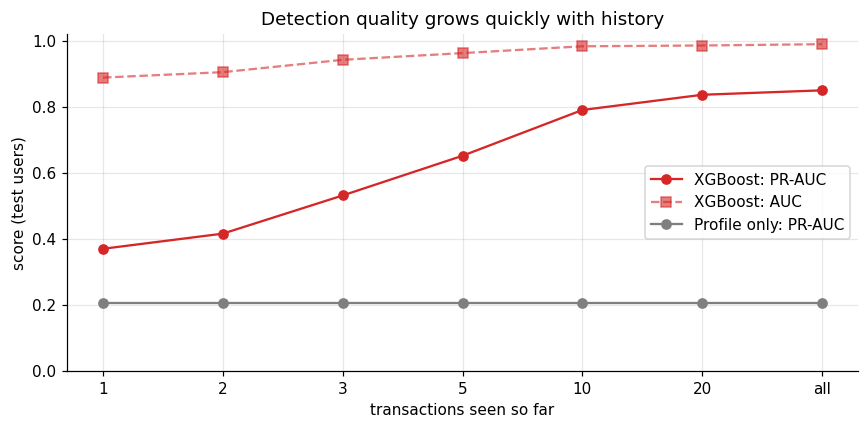

user AUC                                 user PR-AUC                    
model    Profile only (logistic) XGBoost (real-time) Profile only (logistic) XGBoost (real-time)
after tx                                                                                        
1                          0.826               0.889                   0.206               0.370
2                          0.826               0.905                   0.206               0.416
3                          0.826               0.942                   0.206               0.532
5                          0.826               0.963                   0.206               0.652
10                         0.826               0.983                   0.206               0.791
20                         0.826               0.986                   0.206               0.837
all                        0.826               0.990                   0.206               0.850

In [17]:
early = []
for n in [1, 2, 3, 5, 10, 20, None]:
    for name, sc in [('XGBoost (real-time)', score['test']),
                     ('Profile only (logistic)', prof.predict_proba(F.loc[split['test'], PROFILE])[:, 1])]:
        us = user_scores(sc, split['test'], upto=n)
        early.append({'after tx': n or 'all', 'model': name, 'user AUC': roc_auc_score(us.y, us.p),
                      'user PR-AUC': average_precision_score(us.y, us.p)})
early = pd.DataFrame(early)
piv = early.pivot(index='after tx', columns='model', values=['user AUC', 'user PR-AUC']).reindex([1, 2, 3, 5, 10, 20, 'all'])

fig, ax = plt.subplots(figsize=(8, 4))
x = [str(v) for v in piv.index]
ax.plot(x, piv[('user PR-AUC', 'XGBoost (real-time)')], 'o-', color=FRAUD, label='XGBoost: PR-AUC')
ax.plot(x, piv[('user AUC', 'XGBoost (real-time)')], 's--', color=FRAUD, alpha=0.6, label='XGBoost: AUC')
ax.plot(x, piv[('user PR-AUC', 'Profile only (logistic)')], 'o-', color=NORMAL, label='Profile only: PR-AUC')
ax.set_xlabel('transactions seen so far'); ax.set_ylabel('score (test users)'); ax.set_ylim(0, 1.02)
ax.set_title('Detection quality grows quickly with history'); ax.legend()
plt.tight_layout(); plt.savefig(IMG + 'early_detection.png', bbox_inches='tight'); plt.show()
piv.round(3)

After only a handful of transactions the model is far ahead of the profile-only view, and by around
10 transactions it is close to its final quality. Because fraudsters usually start cashing out between their 5th and
10th transaction (section 3), this is exactly the window where catching them pays off.

## 8. Business evaluation: money saved vs. good users disturbed

We replay the test users' transactions in time order, as if the model had been live:

* **Fraud loss** = completed money leaving a fraudster's account (card payments, ATM, bank transfers, P2P).
* **LOCK_USER** at the first transaction where score ≥ `t_lock`: that transaction **and everything after** is blocked.
* **ALERT_AGENT** at the first transaction where score ≥ `t_alert`: nothing is blocked straight away. An agent reviews
  within `REVIEW_HOURS` and locks the account if it is fraud, so only money leaving **after the review** is saved.
* **Costs of mistakes** (assumptions, adjust with the business): each alert costs **$15** of agent time, and wrongly
  locking a genuine user costs **$100** (support call, lost trust, possible churn).

In [18]:
REVIEW_HOURS = 24
ALERT_COST, WRONG_LOCK_COST = 15, 100

OUTFLOW = ['CARD_PAYMENT', 'ATM', 'BANK_TRANSFER', 'P2P']
def replay_table(mask, sc):
    d = t.loc[mask, ['user_id', 'created_date', 'type', 'state', 'amount', 'is_fraud']].copy()
    d['p'] = sc
    d['loss'] = np.where((d.state == 'COMPLETED') & d.type.isin(OUTFLOW), d.amount, 0.0)
    return d

def first_cross(d, thr):
    hit = d[d.p >= thr]
    return hit.groupby('user_id').created_date.min()

def simulate(d, t_alert, t_lock):
    fraud = d[d.is_fraud == 1]
    total_loss = fraud.loss.sum()
    lock_at = first_cross(d, t_lock)
    alert_at = first_cross(d, t_alert)
    # stop time per user: lock -> immediately; alert -> after review
    stop = pd.concat([lock_at, alert_at + pd.Timedelta(hours=REVIEW_HOURS)], axis=1).min(axis=1)
    f = fraud.join(stop.rename('stop'), on='user_id')
    saved = f.loc[f.created_date >= f.stop, 'loss'].sum()
    users_y = d.groupby('user_id').is_fraud.first()
    flagged = alert_at.index.union(lock_at.index)
    good = users_y[users_y == 0].index
    bad = users_y[users_y == 1].index
    alerts = len(flagged)                       # every flagged user is reviewed by an agent
    wrong_locks = len(lock_at.index.intersection(good))
    return {'t_alert': t_alert, 't_lock': t_lock,
            'fraudsters caught %': 100 * len(flagged.intersection(bad)) / len(bad),
            'locked fraudsters': len(lock_at.index.intersection(bad)),
            'alerts': alerts, 'alert precision %': 100 * len(flagged.intersection(bad)) / max(alerts, 1),
            'good users locked': wrong_locks,
            'good users alerted': len(flagged.intersection(good)),
            'fraud loss $': total_loss, 'saved $': saved, 'saved %': 100 * saved / total_loss,
            'net value $': saved - ALERT_COST * alerts - WRONG_LOCK_COST * wrong_locks}

val = replay_table(split['valid'], score['valid'])
grid = [simulate(val, a, l) for a in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
        for l in [0.8, 0.85, 0.9, 0.95, 0.97, 0.99, 1.01] if l > a]   # 1.01 = never lock
grid = pd.DataFrame(grid).sort_values('net value $', ascending=False)
grid.head(8).round(1)

,t_alert,t_lock,fraudsters caught %,locked fraudsters,alerts,alert precision %,good users locked,good users alerted,fraud loss $,saved $,saved %,net value $
4,0.2,1.0,96.6,37,645,8.8,9,588,313923.8,312835.0,99.7,302260.0
3,0.2,1.0,96.6,41,645,8.8,22,588,313923.8,313287.6,99.8,301412.6
2,0.2,0.9,96.6,46,645,8.8,43,588,313923.8,313514.5,99.9,299539.5
25,0.5,1.0,93.2,37,468,11.8,9,413,313923.8,305550.9,97.3,297630.9
1,0.2,0.8,96.6,48,645,8.8,68,588,313923.8,313599.7,99.9,297124.7
18,0.4,1.0,94.9,37,538,10.4,9,482,313923.8,305901.6,97.4,296931.6
24,0.5,1.0,93.2,41,468,11.8,22,413,313923.8,306003.5,97.5,296783.5
5,0.2,1.0,96.6,16,645,8.8,1,588,313923.8,306528.2,97.6,296753.2


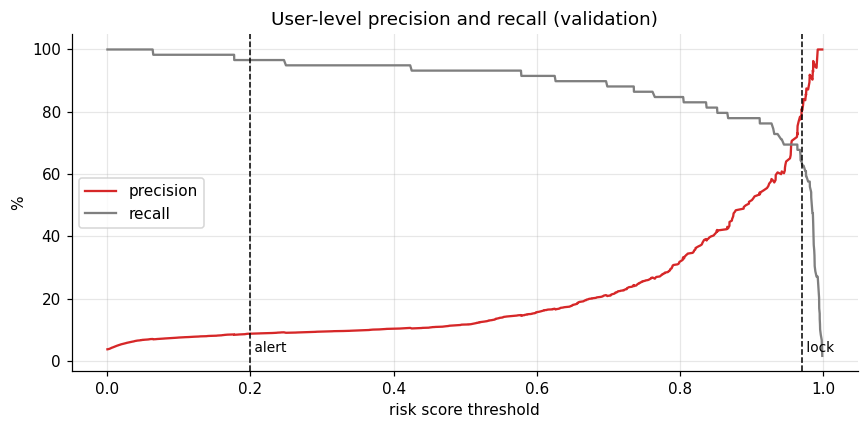

In [19]:
# Precision / recall at user level across thresholds (validation)
uv = val.groupby('user_id').agg(y=('is_fraud', 'first'), p=('p', 'max'))
prec, rec, thr = precision_recall_curve(uv.y, uv.p)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, prec[:-1] * 100, color=FRAUD, label='precision')
ax.plot(thr, rec[:-1] * 100, color=NORMAL, label='recall')
best_row = grid.iloc[0]
for v, lab in [(best_row.t_alert, 'alert'), (best_row.t_lock, 'lock')]:
    if v <= 1:
        ax.axvline(v, color='k', ls='--', lw=1); ax.text(v, 3, f' {lab}', fontsize=9)
ax.set_xlabel('risk score threshold'); ax.set_ylabel('%'); ax.set_title('User-level precision and recall (validation)')
ax.legend(); plt.tight_layout(); plt.savefig(IMG + 'precision_recall_threshold.png', bbox_inches='tight'); plt.show()

In [20]:
T_ALERT, T_LOCK = float(best_row.t_alert), float(best_row.t_lock)
print(f'Chosen on validation: ALERT at score >= {T_ALERT}, LOCK at score >= {T_LOCK}')

test = replay_table(split['test'], score['test'])
compare = pd.DataFrame([
    {'policy': 'No model', **simulate(test, 2, 2)},
    {'policy': 'Alert only', **simulate(test, T_ALERT, 2)},
    {'policy': 'Lock only', **simulate(test, T_LOCK, T_LOCK)},
    {'policy': 'Chosen: alert + lock tiers', **simulate(test, T_ALERT, T_LOCK)},
]).set_index('policy')
compare.round(1)

Chosen on validation: ALERT at score >= 0.2, LOCK at score >= 0.97


,t_alert,t_lock,fraudsters caught %,locked fraudsters,alerts,alert precision %,good users locked,good users alerted,fraud loss $,saved $,saved %,net value $
policy,,,,,,,,,,,,
No model,2.0,2.0,0.0,0,0,0.0,0,0,355392.4,0.0,0.0,0.0
Alert only,0.2,2.0,100.0,0,651,9.2,0,591,355392.4,319411.3,89.9,309646.3
Lock only,1.0,1.0,83.3,50,62,80.6,12,12,355392.4,290356.5,81.7,288226.5
Chosen: alert + lock tiers,0.2,1.0,100.0,50,651,9.2,12,591,355392.4,332572.0,93.6,321607.0


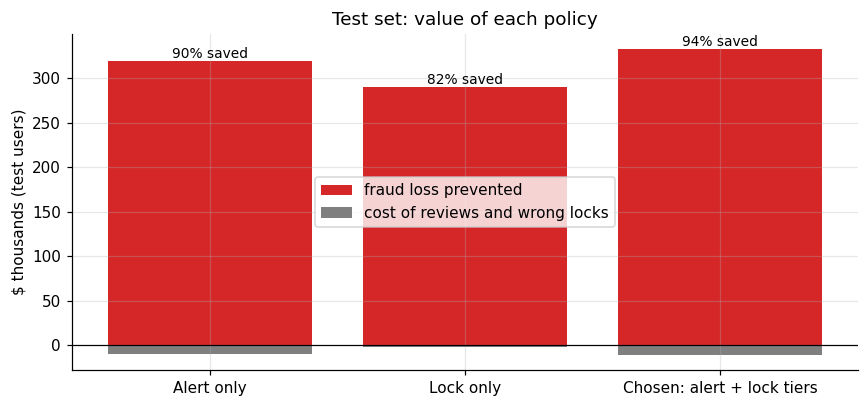

In [21]:
c = compare
fig, ax = plt.subplots(figsize=(8, 3.8))
names = c.index[1:]
ax.bar(names, c.loc[names, 'saved $'] / 1000, color=FRAUD, label='fraud loss prevented')
ax.bar(names, -(ALERT_COST * c.loc[names, 'alerts'] + WRONG_LOCK_COST * c.loc[names, 'good users locked']) / 1000,
       color=NORMAL, label='cost of reviews and wrong locks')
ax.axhline(0, color='k', lw=0.8)
for i, n in enumerate(names):
    ax.text(i, c.loc[n, 'saved $'] / 1000, f"{c.loc[n, 'saved %']:.0f}% saved", ha='center', va='bottom', fontsize=9)
ax.set_ylabel('$ thousands (test users)'); ax.set_title('Test set: value of each policy'); ax.legend()
plt.tight_layout(); plt.savefig(IMG + 'policy_value.png', bbox_inches='tight'); plt.show()

## 9. Operational policy: `patrol(user_id)`

| Risk score | Action | Why |
|---|---|---|
| ≥ `T_LOCK` | **LOCK_USER + ALERT_AGENT** | Very likely a fraudster: block now so money can't leave, and alert an agent so a genuine user who gets locked by mistake is unlocked quickly. |
| ≥ `T_ALERT` | **ALERT_AGENT** | Suspicious but uncertain: let the payment go through and have a human review, so good customers aren't disturbed. |
| below | no action | Keep scoring on every new transaction. |

A lock is never sent without an alert. A locked user can only be restored by an agent anyway, so the agent
should be told straight away rather than wait for an angry support call.

In [22]:
ALL_MOMENTS = t[['user_id']].assign(tx_n=F.tx_n.values)
LATEST = ALL_MOMENTS.groupby('user_id').tx_n.idxmax()     # row of each user's most recent transaction

def patrol(user_id):
    """Suggested actions for a user, based on their profile and all transactions so far."""
    if user_id not in LATEST.index:
        return []                                      # no transactions -> no money at risk yet
    risk = float(model.predict_proba(F.loc[[LATEST[user_id]]])[:, 1][0])
    if risk >= T_LOCK:
        return ['LOCK_USER', 'ALERT_AGENT']
    if risk >= T_ALERT:
        return ['ALERT_AGENT']
    return []

demo = test_u.groupby('is_fraud').head(4).user_id
for uid in demo:
    print(uid[:8], '| fraudster' if users.set_index('id').is_fraud[uid] else '| normal   ', '->', patrol(uid))

2055ff3b | normal    -> []
40d7bf8a | normal    -> []
92b44968 | normal    -> []
79762f9e | normal    -> []
840a2f6a | fraudster -> ['ALERT_AGENT']
3f96bf38 | fraudster -> ['LOCK_USER', 'ALERT_AGENT']
a7fb2215 | fraudster -> ['LOCK_USER', 'ALERT_AGENT']
310667d1 | fraudster -> ['ALERT_AGENT']


## 10. Summary

In [23]:
best_test = compare.loc['Chosen: alert + lock tiers']
xg = results.loc[('test', 'XGBoost (real-time)')]
print(f"Test users: {len(test_u)}  ({test_u.is_fraud.sum()} fraudsters)")
print(f"User-level AUC {xg['user AUC']:.3f}, PR-AUC {xg['user PR-AUC']:.3f}")
print(f"Fraudsters caught: {best_test['fraudsters caught %']:.0f}%, alert precision {best_test['alert precision %']:.0f}%")
print(f"Fraud loss prevented: ${best_test['saved $']:,.0f} of ${best_test['fraud loss $']:,.0f} ({best_test['saved %']:.0f}%)")
print(f"Agent reviews: {best_test['alerts']:.0f},  good users locked: {best_test['good users locked']:.0f}")

Test users: 1550  (60 fraudsters)
User-level AUC 0.990, PR-AUC 0.850
Fraudsters caught: 100%, alert precision 9%
Fraud loss prevented: $332,572 of $355,392 (94%)
Agent reviews: 651,  good users locked: 12


**Limitations and next steps**

* **Small number of fraudsters** (~60 in each of validation and test). Metrics will move a few points with a
  different split; k-fold cross-validation by user would give tighter estimates.
* **No fraud timestamp.** We don't know when each fraudster was actually caught, so "money saved" assumes that
  without the model all of their outflows would have been lost. That is an upper bound on the value.
* **Amounts:** the cents interpretation and the crypto cap are assumptions to confirm with the data owner.
* **Costs** ($15 per review, $100 per wrong lock) are placeholders. The policy grid re-optimises as soon as real numbers are known.
* **Label maturity:** recent sign-ups are under-labelled. In production, retrain on matured cohorts only and monitor drift.
* **Next:** device and IP signals, network features (who sends money to whom via P2P), and an A/B test of the policy.